In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from src.helpers.output_index import sharpe
#from src.utility.generate_datasets import create_df
from src.helpers.download_prices import prices

In [2]:
def drawdown(ret, ret_m):
    
    wea_idx = 1 * (ret + 1).cumprod()
    picos = wea_idx.cummax()

    wea_idx_m = 1 * (ret_m + 1).cumprod()
    picos_m = wea_idx_m.cummax()

    drawdown_default = (wea_idx - picos) / picos
    drawdown_model = (wea_idx_m - picos_m) / picos_m

    return np.round(drawdown_default * 100, 2), np.round(drawdown_model * 100, 2)


In [3]:
# Specify the base directory containing all the action directories
base_dir = 'D:/TCC Lucas/vulture_ai_laboratory/models/basic/'  # Replace with your base directory if different

retorno_rf = pd.DataFrame()
retorno_svm = pd.DataFrame()
retorno_xgb = pd.DataFrame()

v = ['v1.0', 'v2.0', 'v3.0']

randomforest_list = np.loadtxt('./results_tcc/recomend_rf.txt', dtype='str')[:-1]
svm_list = np.loadtxt('./results_tcc/recomend_svm.txt', dtype='str')[:-1]
xgboost_list = np.loadtxt('./results_tcc/recomend_xgboost.txt', dtype='str')[:-1]

for version in v:
    if version=='v1.0':
        algoritmo = 'xgboost'
        stocks = xgboost_list
    elif version=='v2.0':
        algoritmo = 'randomforest'
        stocks = randomforest_list
    else:
        algoritmo = 'svm'
        stocks = svm_list

    for stock in stocks:            
        dir = os.path.join(base_dir, stock+'/'+version)
        file_path = dir+'/'+'report.json'
        
        with open(file_path, 'r') as f:
            data = json.load(f)
        
        data_test = data.get('data')        
        ret = data.get('percent_return')
        ret_model = data.get('percent_return_model')
        lista = []
        [lista.append(stock) for i in range(len(data_test))]
        data_entry = {
            'data': data_test,
            'ticker': lista,
            'percent_return': ret,
            'percent_return_model': ret_model,
        }
        
        if algoritmo=='randomforest':
            df = pd.DataFrame.from_dict(data_entry)
            retorno_rf = pd.concat((retorno_rf, df), axis=0)
        elif algoritmo=='svm':
            df = pd.DataFrame.from_dict(data_entry)
            retorno_svm = pd.concat((retorno_svm, df), axis=0)
        else:
            df = pd.DataFrame.from_dict(data_entry)
            retorno_xgb = pd.concat((retorno_xgb, df), axis=0)

# Create a DataFrame from the collected data
#retorno_rf.set_index('data', inplace=True)
#retorno_svm.set_index('data', inplace=True)
#retorno_xgb.set_index('data', inplace=True)

In [4]:
tickers = {'BOVA11.SA': ["Open", "High", "Low", "Close", "Volume"],}
start = data_test[0]
end = data_test[-1]
bova11 = prices(tickers, start, end, interval="1d", update=False)
bova11['percent_return'] = bova11['Close_BOVA11.SA'].pct_change()

Direct request from vulture datasets: BOVA11.SA


In [5]:
return_cumsum_bova11 = 100*bova11['percent_return'].cumsum()#.item()
sharpe_bova11= sharpe(bova11['percent_return'], len(bova11), 10.75 / 100).item()

In [6]:
print("Ibovespa (BOVA11.SA) - Retorno", return_cumsum_bova11[-1], "Sharpe:", sharpe_bova11)

Ibovespa (BOVA11.SA) - Retorno 20.87490001723127 Sharpe: 0.3403572552686325


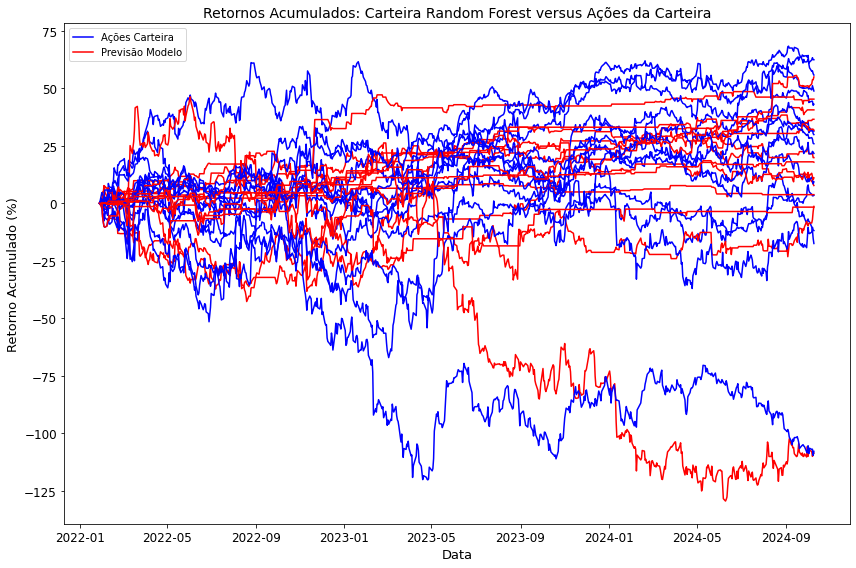

In [7]:
ret_padrao = retorno_rf[retorno_rf['ticker']==randomforest_list[0]]['percent_return'].cumsum()
ret_md = retorno_rf[retorno_rf['ticker']==randomforest_list[0]]['percent_return_model'].cumsum()
data2 = pd.to_datetime(retorno_rf[retorno_rf['ticker']==randomforest_list[0]]['data'])
#data2= pd.to_datetime(data)

plt.figure(figsize=(12,8))
plt.plot(data2, ret_padrao, color='blue')
plt.plot(data2, ret_md, color='red')


for stock in randomforest_list:
    if stock != randomforest_list[0]:
        ret_padrao = retorno_rf[retorno_rf['ticker']==stock]['percent_return'].cumsum()
        ret_md = retorno_rf[retorno_rf['ticker']==stock]['percent_return_model'].cumsum()
        data = retorno_rf[retorno_rf['ticker']==stock]['data']
        data2= pd.to_datetime(data)
        
        plt.plot(data2, ret_padrao, color='blue')
        plt.plot(data2, ret_md, color='red')
        
plt.title('Retornos Acumulados: Carteira Random Forest versus Ações da Carteira', fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=12)
plt.ylabel('Retorno Acumulado (%)', fontsize=13)
plt.xlabel('Data', fontsize=13)
plt.tight_layout()
plt.legend(['Ações Carteira', 'Previsão Modelo'])
#plt.savefig('./results_tcc/retorno_rf_all.png', dpi=300)
plt.show()

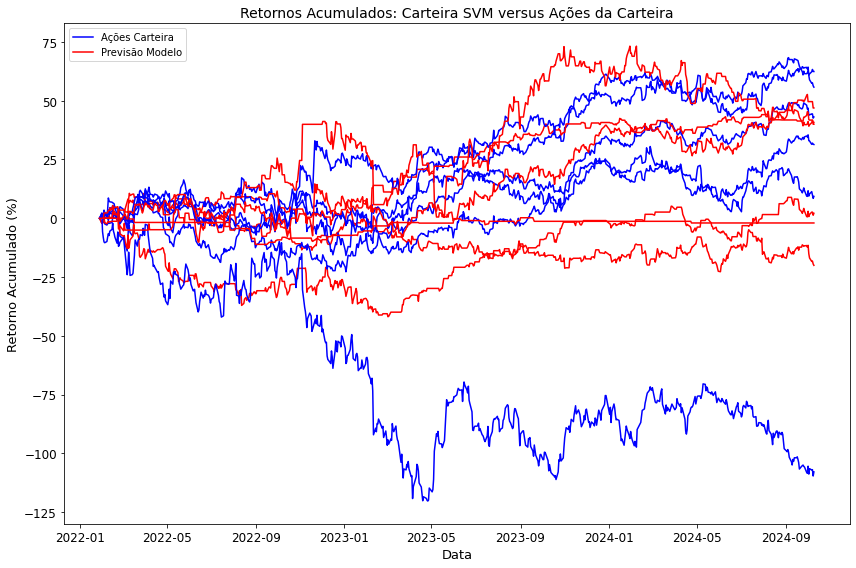

In [8]:
ret_padrao = retorno_svm[retorno_svm['ticker']==svm_list[0]]['percent_return'].cumsum()
ret_md = retorno_svm[retorno_svm['ticker']==svm_list[0]]['percent_return_model'].cumsum()
data2 = pd.to_datetime(retorno_svm[retorno_svm['ticker']==svm_list[0]]['data'])
#data2= pd.to_datetime(data)

plt.figure(figsize=(12,8))
plt.plot(data2, ret_padrao, color='blue')
plt.plot(data2, ret_md, color='red')


for stock in randomforest_list:
    if stock != svm_list[0]:
        ret_padrao = retorno_svm[retorno_svm['ticker']==stock]['percent_return'].cumsum()
        ret_md = retorno_svm[retorno_svm['ticker']==stock]['percent_return_model'].cumsum()
        data = retorno_svm[retorno_svm['ticker']==stock]['data']
        data2= pd.to_datetime(data)
        
        plt.plot(data2, ret_padrao, color='blue')
        plt.plot(data2, ret_md, color='red')
        
plt.title('Retornos Acumulados: Carteira SVM versus Ações da Carteira', fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=12)
plt.ylabel('Retorno Acumulado (%)', fontsize=13)
plt.xlabel('Data', fontsize=13)
plt.tight_layout()
plt.legend(['Ações Carteira', 'Previsão Modelo'])
#plt.savefig('./results_tcc/retorno_svm_all.png', dpi=300)
plt.show()

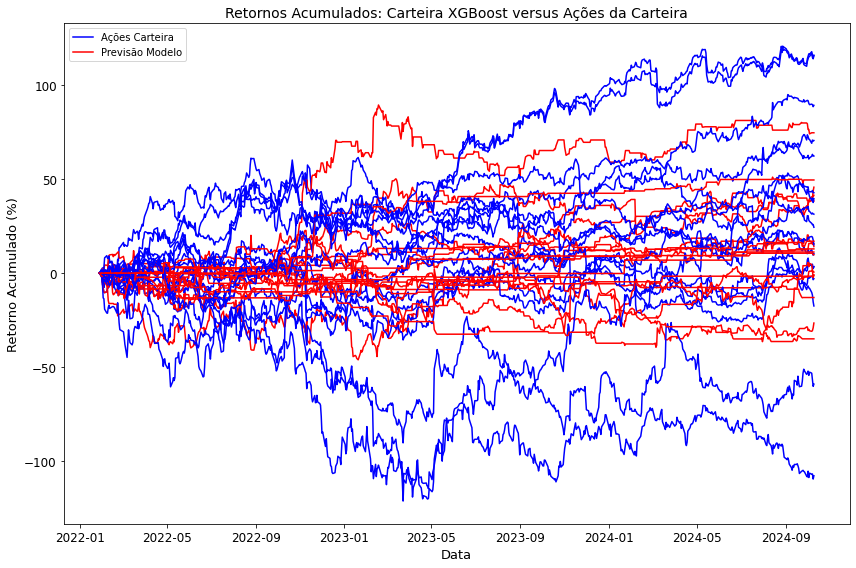

In [9]:
ret_padrao = retorno_xgb[retorno_xgb['ticker']==xgboost_list[0]]['percent_return'].cumsum()
ret_md = retorno_xgb[retorno_xgb['ticker']==xgboost_list[0]]['percent_return_model'].cumsum()
data2 = pd.to_datetime(retorno_xgb[retorno_xgb['ticker']==xgboost_list[0]]['data'])
#data2= pd.to_datetime(data)

plt.figure(figsize=(12,8))
plt.plot(data2, ret_padrao, color='blue')
plt.plot(data2, ret_md, color='red')


for stock in xgboost_list:
    if stock != xgboost_list[0]:
        ret_padrao = retorno_xgb[retorno_xgb['ticker']==stock]['percent_return'].cumsum()
        ret_md = retorno_xgb[retorno_xgb['ticker']==stock]['percent_return_model'].cumsum()
        data = retorno_xgb[retorno_xgb['ticker']==stock]['data']
        data2= pd.to_datetime(data)
        
        plt.plot(data2, ret_padrao, color='blue')
        plt.plot(data2, ret_md, color='red')
        
plt.title('Retornos Acumulados: Carteira XGBoost versus Ações da Carteira', fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=12)
plt.ylabel('Retorno Acumulado (%)', fontsize=13)
plt.xlabel('Data', fontsize=13)
plt.tight_layout()
plt.legend(['Ações Carteira', 'Previsão Modelo'])
#plt.savefig('./results_tcc/retorno_xgb_all.png', dpi=300)
plt.show()

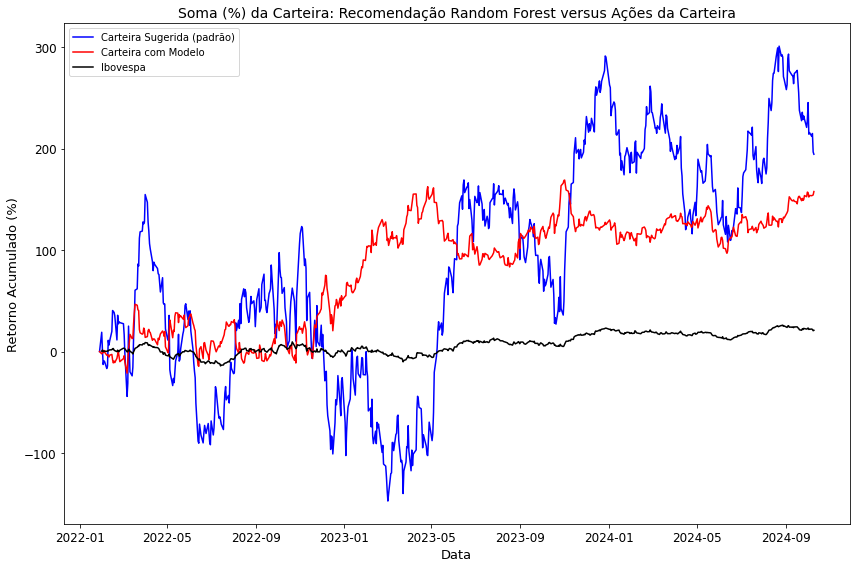

In [10]:
ret_padrao = retorno_rf[retorno_rf['ticker']==randomforest_list[0]]['percent_return']#.cumsum()
ret_md = retorno_rf[retorno_rf['ticker']==randomforest_list[0]]['percent_return_model']#.cumsum()
data2 = pd.to_datetime(retorno_rf[retorno_rf['ticker']==randomforest_list[0]]['data'])

for stock in randomforest_list:
    if stock != randomforest_list[0]:
        ret_padrao += retorno_rf[retorno_rf['ticker']==stock]['percent_return']#.cumsum()
        ret_md += retorno_rf[retorno_rf['ticker']==stock]['percent_return_model']#.cumsum()
        
plt.figure(figsize=(12,8))
plt.plot(data2, ret_padrao.cumsum(), color='blue')
plt.plot(data2, ret_md.cumsum(), color='red')
plt.plot(data2, return_cumsum_bova11, color='black')
plt.title('Soma (%) da Carteira: Recomendação Random Forest versus Ações da Carteira', fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=12)
plt.ylabel('Retorno Acumulado (%)', fontsize=13)
plt.xlabel('Data', fontsize=13)
plt.tight_layout()
plt.legend(['Carteira Sugerida (padrão)', 'Carteira com Modelo', 'Ibovespa'])
#plt.savefig('./results_tcc/retorno_rf_sum.png', dpi=300)
plt.show()

In [11]:
#drawdown_stocks, drawdown_rf = drawdown(ret_padrao, ret_md)
#print("DD - Ativos: ", drawdown_stocks.min(), "Random Forest:", drawdown_rf.min())
#print("")
print("Retornos - Ativos:", ret_padrao.cumsum()[676], "Random Forest:", ret_md.cumsum()[676])
print("")
sp = sharpe(ret_padrao, len(ret_padrao), 10.75 / 100)
sp2 = sharpe(ret_md, len(ret_md), 10.75/100)
print("Sharpe - Ativos: ", sp, "Random Forest:", sp2)

Retornos - Ativos: 194.35411778797453 Random Forest: 157.61969687299572

Sharpe - Ativos:  0.47725603045897275 Random Forest: 1.0178658384658361


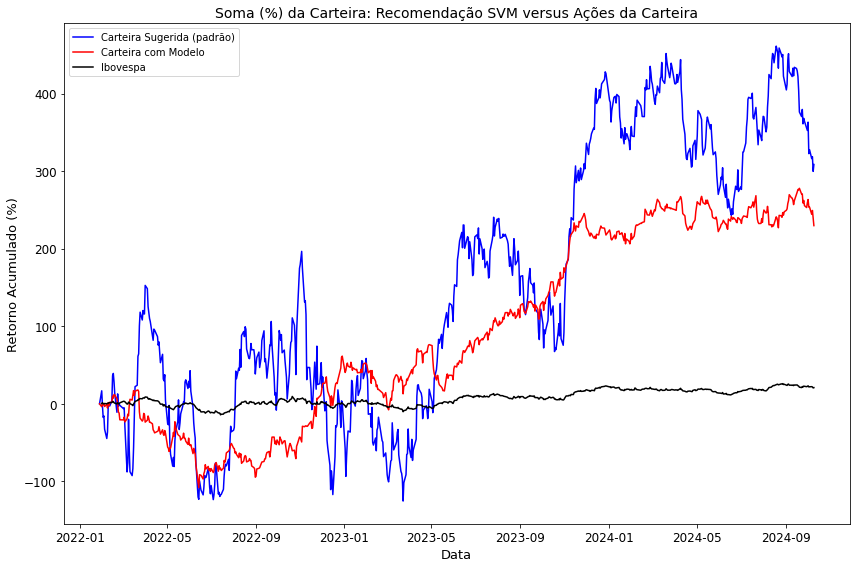

In [12]:
ret_padrao = retorno_svm[retorno_svm['ticker']==svm_list[0]]['percent_return']#.cumsum()
ret_md = retorno_svm[retorno_svm['ticker']==svm_list[0]]['percent_return_model']#.cumsum()
data2 = pd.to_datetime(retorno_svm[retorno_svm['ticker']==svm_list[0]]['data'])

for stock in svm_list:
    if stock != svm_list[0]:
        ret_padrao += retorno_svm[retorno_svm['ticker']==stock]['percent_return']#.cumsum()
        ret_md += retorno_svm[retorno_svm['ticker']==stock]['percent_return_model']#.cumsum()                
        
plt.figure(figsize=(12,8))
plt.plot(data2, ret_padrao.cumsum(), color='blue')
plt.plot(data2, ret_md.cumsum(), color='red')
plt.plot(data2, return_cumsum_bova11, color='black')
plt.title('Soma (%) da Carteira: Recomendação SVM versus Ações da Carteira', fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=12)
plt.ylabel('Retorno Acumulado (%)', fontsize=13)
plt.xlabel('Data', fontsize=13)
plt.tight_layout()
plt.legend(['Carteira Sugerida (padrão)', 'Carteira com Modelo', 'Ibovespa'])
#plt.savefig('./results_tcc/retorno_svm_sum.png', dpi=300)
plt.show()

In [13]:
#drawdown_stocks, drawdown_rf = drawdown(ret_padrao, ret_md)
#print("DD - Ativos: ", drawdown_stocks, "SVM:", drawdown_rf)
#print("")
print("Retornos - Ativos:", ret_padrao.cumsum()[676], "SVM:", ret_md.cumsum()[676])
print("")
sp = sharpe(ret_padrao, len(ret_padrao), 10.75 / 100)
sp2 = sharpe(ret_md, len(ret_md), 10.75/100)

print("Sharpe - Ativos: ", sp, "SVM:", sp2)

Retornos - Ativos: 308.47231320750456 SVM: 229.7095250599218

Sharpe - Ativos:  0.5991856840894683 SVM: 1.357461897736219


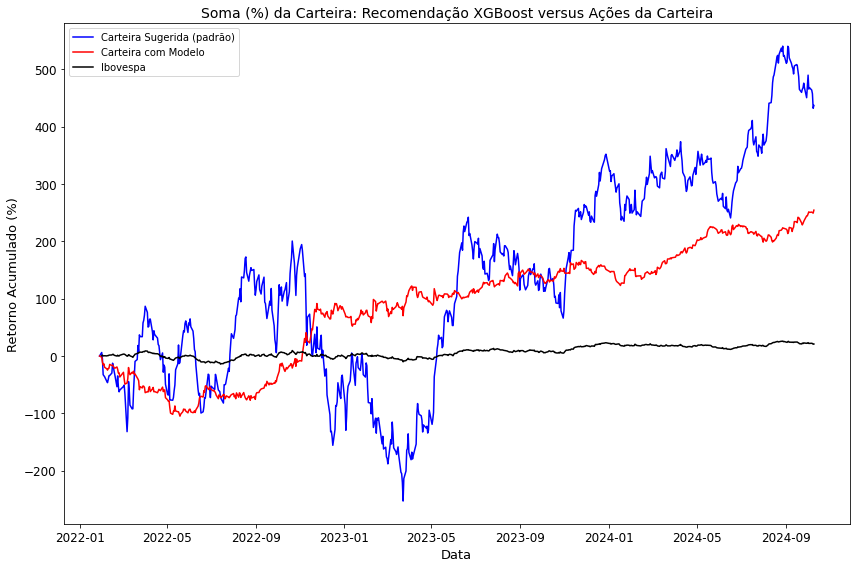

In [14]:
ret_padrao = retorno_xgb[retorno_xgb['ticker']==xgboost_list[0]]['percent_return']#.cumsum()
ret_md = retorno_xgb[retorno_xgb['ticker']==xgboost_list[0]]['percent_return_model']#.cumsum()
data2 = pd.to_datetime(retorno_xgb[retorno_xgb['ticker']==xgboost_list[0]]['data'])

for stock in xgboost_list:
    if stock != xgboost_list[0]:
        ret_padrao += retorno_xgb[retorno_xgb['ticker']==stock]['percent_return']#.cumsum()
        ret_md += retorno_xgb[retorno_xgb['ticker']==stock]['percent_return_model']#.cumsum()                
        
plt.figure(figsize=(12,8))
plt.plot(data2, ret_padrao.cumsum(), color='blue')
plt.plot(data2, ret_md.cumsum(), color='red')
plt.plot(data2, return_cumsum_bova11, color='black')
plt.title('Soma (%) da Carteira: Recomendação XGBoost versus Ações da Carteira', fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=12)
plt.ylabel('Retorno Acumulado (%)', fontsize=13)
plt.xlabel('Data', fontsize=13)
plt.tight_layout()
plt.legend(['Carteira Sugerida (padrão)', 'Carteira com Modelo', 'Ibovespa'])
#plt.savefig('./results_tcc/retorno_xgb_sum.png', dpi=300)
plt.show()

In [15]:
#drawdown_stocks, drawdown_rf = drawdown(ret_padrao, ret_md)
#print("DD - Ativos: ", drawdown_stocks, "XGBoost:", drawdown_rf)
#print("")
print("Retornos - Ativos:", ret_padrao.cumsum()[676], "XGBoost:", ret_md.cumsum()[676])
print("")
sp = sharpe(ret_padrao, len(ret_padrao), 10.75 / 100)
sp2 = sharpe(ret_md, len(ret_md), 10.75/100)

print("Sharpe - Ativos: ", sp, "XGBoost:", sp2)

Retornos - Ativos: 436.99624936351097 XGBoost: 254.4135229239898

Sharpe - Ativos:  0.8923097722215105 XGBoost: 1.7310364369385955
